In [36]:
import os
import sys
import json
import time
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import cv2

from tqdm.auto import tqdm

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090


In [37]:
#Project Paths 
PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

EWIS1_ROOT = (
    PROJECT_ROOT / "EWIS1"
)

EWIS1_OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "ewis1_agriclip_sam2"
)

EWIS1_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("EWIS1:")
print(EWIS1_ROOT)

print("\nOutput:")
print(EWIS1_OUTPUT_DIR)


EWIS1:
/home/zahranadeem/thesis/EWIS1

Output:
/home/zahranadeem/thesis/results/ewis1_agriclip_sam2


In [38]:
from pathlib import Path

PROJECT_ROOT = Path("/home/zahranadeem/thesis")

EWIS1_ROOT = PROJECT_ROOT

EWIS1_ZIP = (
    EWIS1_ROOT /
    "EWIS1 Maize, Sorghum & Weed Dataset.zip"
)

print("ZIP path:", EWIS1_ZIP)
print("ZIP exists:", EWIS1_ZIP.exists())

ZIP path: /home/zahranadeem/thesis/EWIS1 Maize, Sorghum & Weed Dataset.zip
ZIP exists: True


In [39]:
from pathlib import Path
import zipfile

PROJECT_ROOT = Path("/home/zahranadeem/thesis")

# ZIP file location
EWIS1_ZIP = (
    PROJECT_ROOT /
    "EWIS1 Maize, Sorghum & Weed Dataset.zip"
)

# Folder where the dataset will be extracted
EWIS1_ROOT = (
    PROJECT_ROOT /
    "EWIS1"
)

print("ZIP:", EWIS1_ZIP)
print("ZIP exists:", EWIS1_ZIP.exists())
print("Extraction folder:", EWIS1_ROOT)

ZIP: /home/zahranadeem/thesis/EWIS1 Maize, Sorghum & Weed Dataset.zip
ZIP exists: True
Extraction folder: /home/zahranadeem/thesis/EWIS1


In [40]:
# Extract EWIS1 dataset

EWIS1_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

if EWIS1_ZIP.exists():

    print("Extracting EWIS1...")

    with zipfile.ZipFile(
        EWIS1_ZIP,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            EWIS1_ROOT
        )

    print("Extraction complete.")

else:

    print(
        "ZIP not found. "
        "Please place the downloaded EWIS1 ZIP at:"
    )

    print(EWIS1_ZIP)

Extracting EWIS1...


Extraction complete.


In [41]:
print("\nExtracted EWIS1 contents:")

for item in EWIS1_ROOT.iterdir():
    print(item)


Extracted EWIS1 contents:
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset


In [42]:
for path in EWIS1_ROOT.rglob("*"):
    if path.is_file():
        print(path)

/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes.zip
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks.zip
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images.zip
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/img_20210914_D2_2_012.xml
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/Platte_20220520_Maize_048.xml
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/Aholfing_20220525_Sorghum_010.xml
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/img_20210716_B3_1_011.xml
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/Loew_20220511_Maize_024.xml
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/img_20210705_A1_2_003.xml
/home/z

In [43]:
#Inspect the extracted contents 
print("EWIS1 contents:\n")

for p in EWIS1_ROOT.rglob("*"):

    relative = p.relative_to(
        EWIS1_ROOT
    )

    print(
        relative,
        "->",
        "DIR" if p.is_dir() else "FILE"
    )



EWIS1 contents:

EWIS1 Maize, Sorghum & Weed Dataset -> DIR
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes -> DIR
EWIS1 Maize, Sorghum & Weed Dataset/images -> DIR
EWIS1 Maize, Sorghum & Weed Dataset/additional_images -> DIR
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes.zip -> FILE
EWIS1 Maize, Sorghum & Weed Dataset/masks.zip -> FILE
EWIS1 Maize, Sorghum & Weed Dataset/images.zip -> FILE
EWIS1 Maize, Sorghum & Weed Dataset/masks -> DIR
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes -> DIR
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/img_20210914_D2_2_012.xml -> FILE
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/Platte_20220520_Maize_048.xml -> FILE
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/Aholfing_20220525_Sorghum_010.xml -> FILE
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes/img_20210716_B3_1_011.xml -> FILE
EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes

In [44]:
# Define EWIS1_DATASET_DIR pointing to the folder inside EWIS1_ROOT
EWIS1_DATASET_DIR = EWIS1_ROOT / "EWIS1 Maize, Sorghum & Weed Dataset"

# EWIS1 extracted directories
EWIS1_IMAGE_DIR = EWIS1_DATASET_DIR / "images" / "images"
EWIS1_MASK_DIR = EWIS1_DATASET_DIR / "masks" / "masks"
EWIS1_BBOX_DIR = EWIS1_DATASET_DIR / "bounding_boxes" / "bounding_boxes"

In [45]:
# EWIS1 extracted directories

EWIS1_IMAGE_DIR = (
    EWIS1_DATASET_DIR /
    "images" /
    "images"
)

EWIS1_MASK_DIR = (
    EWIS1_DATASET_DIR /
    "masks" /
    "masks"
)

EWIS1_BBOX_DIR = (
    EWIS1_DATASET_DIR /
    "bounding_boxes" /
    "bounding_boxes"
)

print("EWIS1 directories:")
print(
    "IMAGE DIR:",
    EWIS1_IMAGE_DIR
)

print(
    "MASK DIR:",
    EWIS1_MASK_DIR
)

print(
    "BBOX DIR:",
    EWIS1_BBOX_DIR
)

print("\nExistence:")
print(
    "Images:",
    EWIS1_IMAGE_DIR.exists()
)

print(
    "Masks:",
    EWIS1_MASK_DIR.exists()
)

print(
    "Bounding boxes:",
    EWIS1_BBOX_DIR.exists()
)

EWIS1 directories:
IMAGE DIR: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
MASK DIR: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks
BBOX DIR: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes

Existence:
Images: True
Masks: True
Bounding boxes: True


In [46]:
import zipfile

# Output directories
EWIS1_IMAGES_DIR = (
    EWIS1_DATASET_DIR /
    "images"
)

EWIS1_MASKS_DIR = (
    EWIS1_DATASET_DIR /
    "masks"
)

EWIS1_BOXES_DIR = (
    EWIS1_DATASET_DIR /
    "bounding_boxes"
)

# Create directories
EWIS1_IMAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EWIS1_MASKS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EWIS1_BOXES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [47]:
from pathlib import Path

# Base project path
PROJECT_ROOT = Path("/home/zahranadeem/thesis")
EWIS1_ROOT = PROJECT_ROOT / "EWIS1"

# Define ZIP file paths (adjust filename strings if yours are named differently)
EWIS1_IMAGES_ZIP = PROJECT_ROOT / "images.zip"
EWIS1_MASKS_ZIP  = PROJECT_ROOT / "masks.zip"
EWIS1_BOXES_ZIP  = PROJECT_ROOT / "bounding_boxes.zip"

# Define extraction target directories
EWIS1_IMAGES_DIR = EWIS1_ROOT / "images"
EWIS1_MASKS_DIR  = EWIS1_ROOT / "masks"
EWIS1_BOXES_DIR  = EWIS1_ROOT / "bounding_boxes"

# Helper function
def extract_zip(zip_path, output_dir, name):
    if not zip_path.exists():
        print(f"{name} ZIP not found at:\n{zip_path}\n")
        return

    print(f"Extracting {name}...")
    output_dir.mkdir(parents=True, exist_ok=True)
    
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(output_dir)

    print(f"{name} extraction complete.\n")

# Call the function
extract_zip(EWIS1_IMAGES_ZIP, EWIS1_IMAGES_DIR, "Images")
extract_zip(EWIS1_MASKS_ZIP, EWIS1_MASKS_DIR, "Masks")
extract_zip(EWIS1_BOXES_ZIP, EWIS1_BOXES_DIR, "Bounding boxes")

Images ZIP not found at:
/home/zahranadeem/thesis/images.zip

Masks ZIP not found at:
/home/zahranadeem/thesis/masks.zip

Bounding boxes ZIP not found at:
/home/zahranadeem/thesis/bounding_boxes.zip



In [48]:
# Correct EWIS1 extracted directories

EWIS1_IMAGE_DIR = (
    EWIS1_DATASET_DIR /
    "images" /
    "images"
)

EWIS1_MASK_DIR = (
    EWIS1_DATASET_DIR /
    "masks" /
    "masks"
)

EWIS1_BBOX_DIR = (
    EWIS1_DATASET_DIR /
    "bounding_boxes" /
    "bounding_boxes"
)

print("EWIS1 directories:")
print(
    "IMAGE DIR:",
    EWIS1_IMAGE_DIR
)

print(
    "MASK DIR:",
    EWIS1_MASK_DIR
)

print(
    "BBOX DIR:",
    EWIS1_BBOX_DIR
)

print("\nExistence:")
print(
    "Images:",
    EWIS1_IMAGE_DIR.exists()
)

print(
    "Masks:",
    EWIS1_MASK_DIR.exists()
)

print(
    "Bounding boxes:",
    EWIS1_BBOX_DIR.exists()
)

EWIS1 directories:
IMAGE DIR: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
MASK DIR: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks
BBOX DIR: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes

Existence:
Images: True
Masks: True
Bounding boxes: True


In [49]:
# Build EWIS1 image-mask pairs

ewis1_pairs = []

image_files = sorted(
    [
        p
        for p in EWIS1_IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ]
)

for image_path in image_files:

    mask_path = (
        EWIS1_MASK_DIR /
        image_path.name
    )

    if mask_path.exists():

        ewis1_pairs.append(
            {
                "image": image_path,
                "mask": mask_path,
            }
        )

print(
    "Total images:",
    len(image_files)
)

print(
    "Matched image-mask pairs:",
    len(ewis1_pairs)
)

print(
    "Unmatched images:",
    len(image_files) -
    len(ewis1_pairs)
)

print("\nFirst 10 pairs:")

for pair in ewis1_pairs[:10]:

    print(
        pair["image"].name,
        "↔",
        pair["mask"].name
    )

Total images: 88
Matched image-mask pairs: 88
Unmatched images: 0

First 10 pairs:
Aholfing_20220525_Sorghum_008.png ↔ Aholfing_20220525_Sorghum_008.png
Aholfing_20220525_Sorghum_010.png ↔ Aholfing_20220525_Sorghum_010.png
Loew_20220505_Maize_006.png ↔ Loew_20220505_Maize_006.png
Loew_20220505_Maize_012.png ↔ Loew_20220505_Maize_012.png
Loew_20220505_Maize_018.png ↔ Loew_20220505_Maize_018.png
Loew_20220505_Maize_024.png ↔ Loew_20220505_Maize_024.png
Loew_20220509_Maize_006.png ↔ Loew_20220509_Maize_006.png
Loew_20220509_Maize_014.png ↔ Loew_20220509_Maize_014.png
Loew_20220509_Maize_020.png ↔ Loew_20220509_Maize_020.png
Loew_20220509_Maize_026.png ↔ Loew_20220509_Maize_026.png


In [50]:
#EWIS1 loader 
#Making weed = foreground i.e. 1  and we crop = ignore 
def get_ewis1_image(index):

    pair = ewis1_pairs[index]

    image = Image.open(
        pair["image"]
    ).convert("RGB")

    return image


In [51]:
#Weed mask loader 
#using PIL to avoid accidentral channel swapping as openCV BGR 
def get_ewis1_mask(index):

    pair = ewis1_pairs[index]

    mask_rgb = np.array(
        Image.open(
            pair["mask"]
        ).convert("RGBA")
    )

    rgb = mask_rgb[:, :, :3]
    alpha = mask_rgb[:, :, 3]

    # EWIS1 official colors
    # Crop  = RGB (31, 119, 180)
    # Weed  = RGB (255, 127, 14)

    weed_pixels = (
        (rgb[:, :, 0] == 255) &
        (rgb[:, :, 1] == 127) &
        (rgb[:, :, 2] == 14) &
        (alpha > 0)
    )

    weed_mask = (
        weed_pixels
        .astype(np.uint8)
    )

    return weed_mask



In [52]:
#Verify 1 sample 
image = get_ewis1_image(0)

gt_mask = get_ewis1_mask(0)

print(
    "Image size:",
    image.size
)

print(
    "Mask shape:",
    gt_mask.shape
)

print(
    "Mask values:",
    np.unique(gt_mask)
)

print(
    "Weed pixels:",
    gt_mask.sum()
)



Image size: (5464, 3640)
Mask shape: (3640, 5464)
Mask values: [0 1]
Weed pixels: 48261


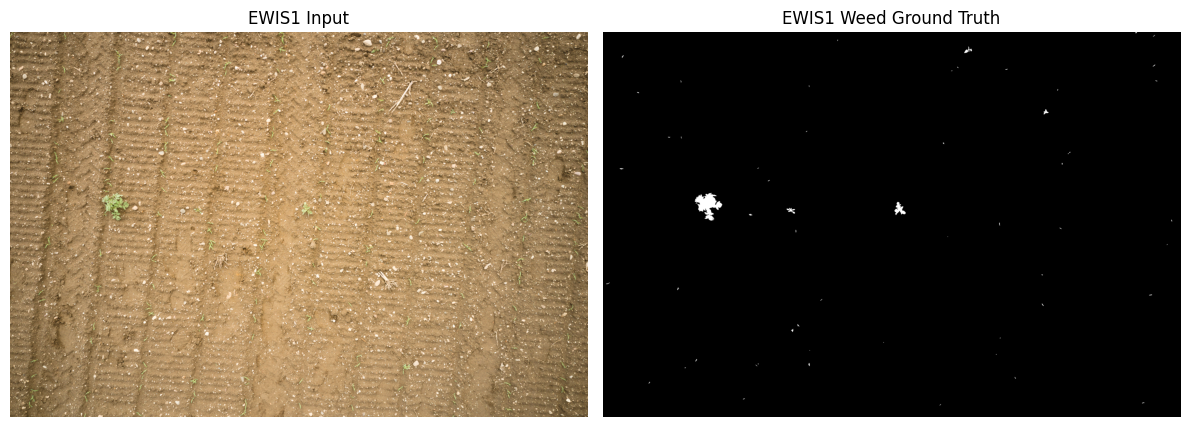

In [53]:
#Visualize GT mask 
fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 6)
)

ax[0].imshow(image)
ax[0].set_title(
    "EWIS1 Input"
)
ax[0].axis("off")

ax[1].imshow(
    gt_mask,
    cmap="gray"
)
ax[1].set_title(
    "EWIS1 Weed Ground Truth"
)
ax[1].axis("off")

plt.tight_layout()
plt.show()

## AGRICLIP + SAM2 PIPELINE

In [54]:
#Checking the device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [55]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

DINO loaded.


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [56]:
import os

print(os.path.exists("/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment/TextToConcept.py"))

True


In [57]:
import clip

print("CLIP imported successfully")
print(clip.available_models())

CLIP imported successfully
['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']


In [58]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print("Python path:")
print(sys.path[0])

Python path:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment


In [59]:
# AgriCLIP alignment paths

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

# YOUR FINE-TUNED VEGANN ALIGNER
ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

print("AgriCLIP root:")
print(AGRICLIP_ROOT)

print("\nAlignment directory:")
print(ALIGNMENT_DIR)

print("\nVegAnn aligner:")
print(ALIGNER_PATH)

print(
    "\nAligner exists:",
    ALIGNER_PATH.exists()
)

AgriCLIP root:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP

Alignment directory:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment

VegAnn aligner:
/home/zahranadeem/thesis/vegann_aligner.pth

Aligner exists: True


In [60]:
# Import AgriCLIP alignment modules

import sys

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(ALIGNMENT_DIR)
    )

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print(
    "TextToConcept imported successfully."
)

print(
    "LinearAligner imported successfully."
)

TextToConcept imported successfully.
LinearAligner imported successfully.


In [61]:
# Load the fine-tuned VegAnn alignment model

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = (
    text_to_concept.linear_aligner
)

print(
    "VegAnn aligner loaded successfully!"
)

print(
    "Aligner type:",
    type(aligner)
)

print(
    "W shape:",
    tuple(aligner.W.shape)
)

print(
    "b shape:",
    tuple(aligner.b.shape)
)

VegAnn aligner loaded successfully!
Aligner type: <class 'LinearAligner.LinearAligner'>
W shape: (512, 2048)
b shape: (512,)


In [62]:
import sys

ALIGNMENT_DIR = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
if ALIGNMENT_DIR not in sys.path:
    sys.path.append(ALIGNMENT_DIR)

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [63]:
# Project DINO patch features using the fine-tuned
# VegAnn alignment model

@torch.no_grad()
def align_patch_features(
    patch_features
):

    patch_features = (
        patch_features
        .float()
        .to(device)
    )

    aligned_features = (
        aligner.get_aligned_representation(
            patch_features
        )
    )

    # Normalize in the shared AgriCLIP concept space
    aligned_features = F.normalize(
        aligned_features,
        dim=1
    )

    return aligned_features

In [64]:
print("===== ALIGNER CHECK =====")

print(
    "Path:",
    ALIGNER_PATH
)

print(
    "Exists:",
    ALIGNER_PATH.exists()
)

print(
    "Aligner:",
    type(aligner)
)

print(
    "W:",
    tuple(aligner.W.shape)
)

print(
    "b:",
    tuple(aligner.b.shape)
)

===== ALIGNER CHECK =====
Path: /home/zahranadeem/thesis/vegann_aligner.pth
Exists: True
Aligner: <class 'LinearAligner.LinearAligner'>
W: (512, 2048)
b: (512,)


In [65]:
#Register a hook on Dino layer4
captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()


hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [66]:
#Extract spatial DINO descriptors automatically wheter 7x7 or other
@torch.no_grad()
def extract_dino_patch_features(pil_image):
    
    

    global captured_feature_map

    captured_feature_map = None

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError(
            "The layer4 hook did not capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map shape (B, C, H, W), "
            f"but received {captured_feature_map.shape}."
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

In [67]:

    

# ============================================================
# PPOSITIVE / NEGATIVE
# ============================================================

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [68]:

# ============================================================
# ENCODE POSITIVE AND NEGATIVE PROMPT SETS
# ============================================================



import torch.nn.functional as F

print("✓ torch.nn.functional imported as F")
@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

✓ torch.nn.functional imported as F
Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])
Final vegetation embedding: torch.Size([512])


In [69]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print(sys.path[0])

/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment


In [70]:
from torchvision import transforms

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

print("DINO transform recreated.")

DINO transform recreated.


In [71]:
#Create forward hook 
captured_feature_map = None

def capture_layer4_output(
    module,
    inputs,
    output
):
    global captured_feature_map
    captured_feature_map = output.detach()

hook_handle = (
    dino_model.layer4.register_forward_hook(
        capture_layer4_output
    )
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [72]:
# Verify DINO extraction on EWIS1

# Get the first EWIS1 image
image_path = ewis1_pairs[0]["image"]

image = Image.open(
    image_path
).convert("RGB")

print(
    "EWIS1 image:",
    image_path.name
)

print(
    "Image size:",
    image.size
)

# Extract DINO Layer-4 spatial features
patch_features, grid_h, grid_w = (
    extract_dino_patch_features(
        image
    )
)

print(
    "Feature grid:",
    grid_h,
    "x",
    grid_w
)

print(
    "Patch features:",
    patch_features.shape
)

EWIS1 image: Aholfing_20220525_Sorghum_008.png
Image size: (5464, 3640)
Feature grid: 7 x 7
Patch features: torch.Size([49, 2048])


In [73]:
# SAM2 imports

import torch
from transformers import (
    Sam2Model,
    Sam2Processor,
)

print("SAM2 classes imported successfully.")

SAM2 classes imported successfully.


In [74]:
# Project Paths

from pathlib import Path

PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

MODEL_NAME = (
    "facebook/sam2.1-hiera-tiny"
)

# --------------------------------------------------
# EWIS1
# --------------------------------------------------

EWIS1_ROOT = (
    PROJECT_ROOT / "EWIS1"
)

EWIS1_OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "ewis1_agriclip_sam2"
)

EWIS1_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# --------------------------------------------------
# Fine-tuned SAM2 checkpoint
# --------------------------------------------------

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

print("EWIS1:")
print(EWIS1_ROOT)

print("\nOutput:")
print(EWIS1_OUTPUT_DIR)

print("\nSAM2 checkpoint:")
print(SAM2_CHECKPOINT)

print(
    "Checkpoint exists:",
    SAM2_CHECKPOINT.exists()
)

EWIS1:
/home/zahranadeem/thesis/EWIS1

Output:
/home/zahranadeem/thesis/results/ewis1_agriclip_sam2

SAM2 checkpoint:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Checkpoint exists: True


In [75]:
#Load fine tuned SAM2 model 
sam2_processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    MODEL_NAME
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
)

print("SAM2 checkpoint type:", type(sam2_checkpoint))

if (
    isinstance(sam2_checkpoint, dict)
    and "mask_decoder_state_dict" in sam2_checkpoint
):
    mask_decoder_state_dict = sam2_checkpoint[
        "mask_decoder_state_dict"
    ]
elif isinstance(sam2_checkpoint, dict):
    # Supports a checkpoint that directly contains decoder weights.
    mask_decoder_state_dict = sam2_checkpoint
else:
    raise TypeError(
        "Unsupported SAM2 checkpoint structure."
    )

load_result = sam2_model.mask_decoder.load_state_dict(
    mask_decoder_state_dict,
    strict=True,
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("Fine-tuned SAM2 mask decoder loaded.")
print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 checkpoint type: <class 'dict'>
Fine-tuned SAM2 mask decoder loaded.
<All keys matched successfully>


In [77]:
# SAM2 prediction from AgriCLIP-generated bounding box



import inspect

print(
    "sam2_predict_box() redefined successfully."
)

print(
    "Function signature:",
    inspect.signature(
        sam2_predict_box
    )
)

@torch.no_grad()
def sam2_predict_box(
    image,
    input_box,
    threshold=0.5
):

    # ----------------------------------------
    # Prepare SAM2 input
    # ----------------------------------------

    sam2_inputs = sam2_processor(
        images=image,
        input_boxes=[
            [input_box.tolist()]
        ],
        return_tensors="pt"
    )

    sam2_inputs = {
        k: v.to(device)
        if torch.is_tensor(v)
        else v
        for k, v in sam2_inputs.items()
    }

    # ----------------------------------------
    # SAM2 inference
    # ----------------------------------------

    sam2_outputs = sam2_model(
        **sam2_inputs
    )

    # ----------------------------------------
    # Select best mask candidate
    # ----------------------------------------

    best_candidate_index = int(
        sam2_outputs
        .iou_scores[0, 0]
        .argmax()
        .item()
    )

    best_logits = (
        sam2_outputs.pred_masks[
            0,
            0,
            best_candidate_index
        ]
    )

    # ----------------------------------------
    # Convert logits → probability
    # ----------------------------------------

    probability = torch.sigmoid(
        best_logits
    )

    # ----------------------------------------
    # Recover original image size
    # ----------------------------------------

    original_height = int(
        sam2_inputs[
            "original_sizes"
        ][0, 0].item()
    )

    original_width = int(
        sam2_inputs[
            "original_sizes"
        ][0, 1].item()
    )

    # ----------------------------------------
    # Resize prediction to original image
    # ----------------------------------------

    probability = F.interpolate(
        probability[None, None],
        size=(
            original_height,
            original_width
        ),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    # ----------------------------------------
    # Threshold probability
    # ----------------------------------------

    prediction = (
        probability >= threshold
    ).cpu().numpy().astype(
        np.uint8
    )

    # ----------------------------------------
    # SAM2 confidence
    # ----------------------------------------

    confidence = float(
        sam2_outputs
        .iou_scores[
            0,
            0,
            best_candidate_index
        ]
        .item()
    )

    return (
        prediction,
        probability.cpu().numpy(),
        confidence
    )


print(
    "sam2_predict_box() redefined successfully."
)

print(
    inspect.signature(
        sam2_predict_box
    )
)




sam2_predict_box() redefined successfully.
Function signature: (image, input_box, threshold=0.5)
sam2_predict_box() redefined successfully.
(image, input_box, threshold=0.5)


In [78]:
#checking existing documents 
required_objects = [
    "device",
    "dino_model",
    "dino_transform",
    "text_to_concept",
    "aligner",
    "vegetation_embedding",
    "sam2_processor",
    "sam2_model",
    "generate_agriclip_box",
    "sam2_predict_box",
]

for name in required_objects:

    print(
        f"{name:30s}:",
        "OK" if name in globals()
        else "MISSING"
    )

device                        : OK
dino_model                    : OK
dino_transform                : OK
text_to_concept               : OK
aligner                       : OK
vegetation_embedding          : OK
sam2_processor                : OK
sam2_model                    : OK
generate_agriclip_box         : MISSING
sam2_predict_box              : OK


In [ ]:
# Project DINO patches using the fine-tuned VegAnn aligner
# The projection maps DINO spatial features into the AgriCLIP concept space.
# Normalize only after the learned projection.

@torch.no_grad()
def align_patch_features(patch_features):

    patch_features = patch_features.float().to(device)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    return aligned_features

In [79]:
#AGRICLIP box generator 
@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k=32,
    margin=25
):

    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(
            image
        )
    )

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )

    scores = (
        aligned_features
        @ vegetation_embedding
    )

    scores_np = (
        scores.detach()
        .cpu()
        .numpy()
    )

    top_k = min(
        top_k,
        len(scores_np)
    )

    topk_indices = (
        np.argsort(
            scores_np
        )[::-1][:top_k]
    )

    image_width, image_height = (
        image.size
    )

    patch_width = (
        image_width / grid_w
    )

    patch_height = (
        image_height / grid_h
    )

    boxes = []

    for idx in topk_indices:

        row = (
            idx // grid_w
        )

        col = (
            idx % grid_w
        )

        x1 = int(
            col * patch_width
        )

        y1 = int(
            row * patch_height
        )

        x2 = int(
            (col + 1)
            * patch_width
        )

        y2 = int(
            (row + 1)
            * patch_height
        )

        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )

    boxes = np.array(
        boxes,
        dtype=np.int32
    )

    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()

    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        image_width - 1,
        xmax + margin
    )

    ymax = min(
        image_height - 1,
        ymax + margin
    )

    agriclip_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )

    return (
        agriclip_box,
        boxes,
        scores_np,
        topk_indices
    )
    

In [83]:
# ============================================================
# TEST AgriCLIP BOX ON EWI1S
# ============================================================

image = get_ewis1_image(0)

# generate_agriclip_box() returns a tuple:
# (agriclip_box, patch_boxes, scores, topk_indices)

(
    agriclip_box,
    boxes,
    scores,
    topk_indices
) = generate_agriclip_box(
    image,
    top_k=32,
    margin=25
)

print("=" * 70)
print("EWI1S AgriCLIP Box Test")
print("=" * 70)

print(
    "Image size:",
    image.size
)

print(
    "AgriCLIP merged box:",
    agriclip_box
)

print(
    "Number of selected patches:",
    len(boxes)
)

print(
    "Top-K indices:",
    topk_indices
)

print(
    "Top-K scores:",
    scores[topk_indices]
)

print("=" * 70)

EWI1S AgriCLIP Box Test
Image size: (5464, 3640)
AgriCLIP merged box: [   0    0 5463 3639]
Number of selected patches: 32
Top-K indices: [35 46 38 39 28 45 41 40 21 37 14 16 43 23 31 47  1 30 10 32 34 17 36 29
  5  3 44 13 20 22  9 15]
Top-K scores: [0.10853549 0.10704285 0.10688877 0.10306141 0.10284986 0.09982309
 0.09692463 0.09247835 0.09196161 0.08614287 0.0810651  0.07976739
 0.0792195  0.07894347 0.07793066 0.07753514 0.07578602 0.07538079
 0.07313113 0.07237445 0.07177913 0.07105099 0.07024687 0.0697093
 0.06917968 0.06601221 0.06548799 0.06399818 0.06127868 0.06077835
 0.06030291 0.05834519]


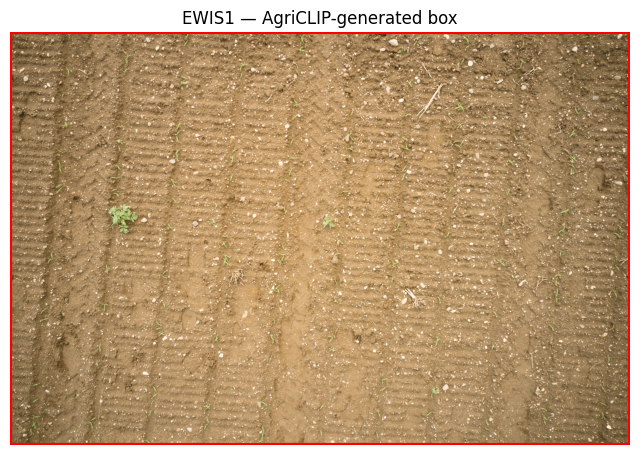

In [84]:
#Visualize AgriCLIP box 
fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.imshow(image)

x1, y1, x2, y2 = agriclip_box

ax.add_patch(
    plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=3
    )
)

ax.set_title(
    "EWIS1 — AgriCLIP-generated box"
)

ax.axis("off")

plt.show()

In [86]:
#SAM2 prediction 
gt_mask = get_ewis1_mask(0)

(
    pred_mask,
    probability,
    confidence
) = sam2_predict_box(
    image,
    agriclip_box,
    threshold=0.5
)

print(
    "Prediction shape:",
    pred_mask.shape
)

print(
    "GT shape:",
    gt_mask.shape
)

print(
    "SAM2 confidence:",
    confidence
)

Prediction shape: (3640, 5464)
GT shape: (3640, 5464)
SAM2 confidence: 0.8138925433158875


In [88]:
# ============================================================
# BOX IoU
# ============================================================

def compute_box_iou(
    pred_box,
    gt_mask
):

    pred_x1, pred_y1, pred_x2, pred_y2 = (
        pred_box
    )

    ys, xs = np.where(
        gt_mask > 0
    )

    if len(xs) == 0:
        return 0.0

    gt_x1 = xs.min()
    gt_y1 = ys.min()
    gt_x2 = xs.max()
    gt_y2 = ys.max()

    # Intersection
    ix1 = max(
        pred_x1,
        gt_x1
    )

    iy1 = max(
        pred_y1,
        gt_y1
    )

    ix2 = min(
        pred_x2,
        gt_x2
    )

    iy2 = min(
        pred_y2,
        gt_y2
    )

    intersection_width = max(
        0,
        ix2 - ix1
    )

    intersection_height = max(
        0,
        iy2 - iy1
    )

    intersection = (
        intersection_width
        * intersection_height
    )

    # Areas
    pred_area = (
        max(0, pred_x2 - pred_x1)
        *
        max(0, pred_y2 - pred_y1)
    )

    gt_area = (
        max(0, gt_x2 - gt_x1)
        *
        max(0, gt_y2 - gt_y1)
    )

    union = (
        pred_area
        +
        gt_area
        -
        intersection
    )

    if union <= 0:
        return 0.0

    return float(
        intersection / union
    )

In [89]:
box_iou = compute_box_iou(
    agriclip_box,
    gt_mask
)

print(
    f"AgriCLIP Box IoU: {box_iou * 100:.2f}%"
)

AgriCLIP Box IoU: 94.99%


In [90]:
#Metrics 
def compute_binary_metrics(
    prediction,
    ground_truth
):

    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(
        prediction,
        ground_truth
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    denominator = (
        pred_pixels + gt_pixels
    )

    dice = (
        2.0 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(intersection),
        "union": int(union),
        "pred_pixels": int(pred_pixels),
        "gt_pixels": int(gt_pixels),
    }

In [91]:
#Test metrics on 1 image 
ewis1_metrics = compute_binary_metrics(
    pred_mask,
    gt_mask
)

for name, value in ewis1_metrics.items():

    if isinstance(value, float):

        print(
            f"{name:>15}: "
            f"{value:.4f}"
        )

    else:

        print(
            f"{name:>15}: "
            f"{value}"
        )

            iou: 0.1396
           dice: 0.2450
      precision: 0.1441
         recall: 0.8187
   intersection: 39513
          union: 282990
    pred_pixels: 274242
      gt_pixels: 48261


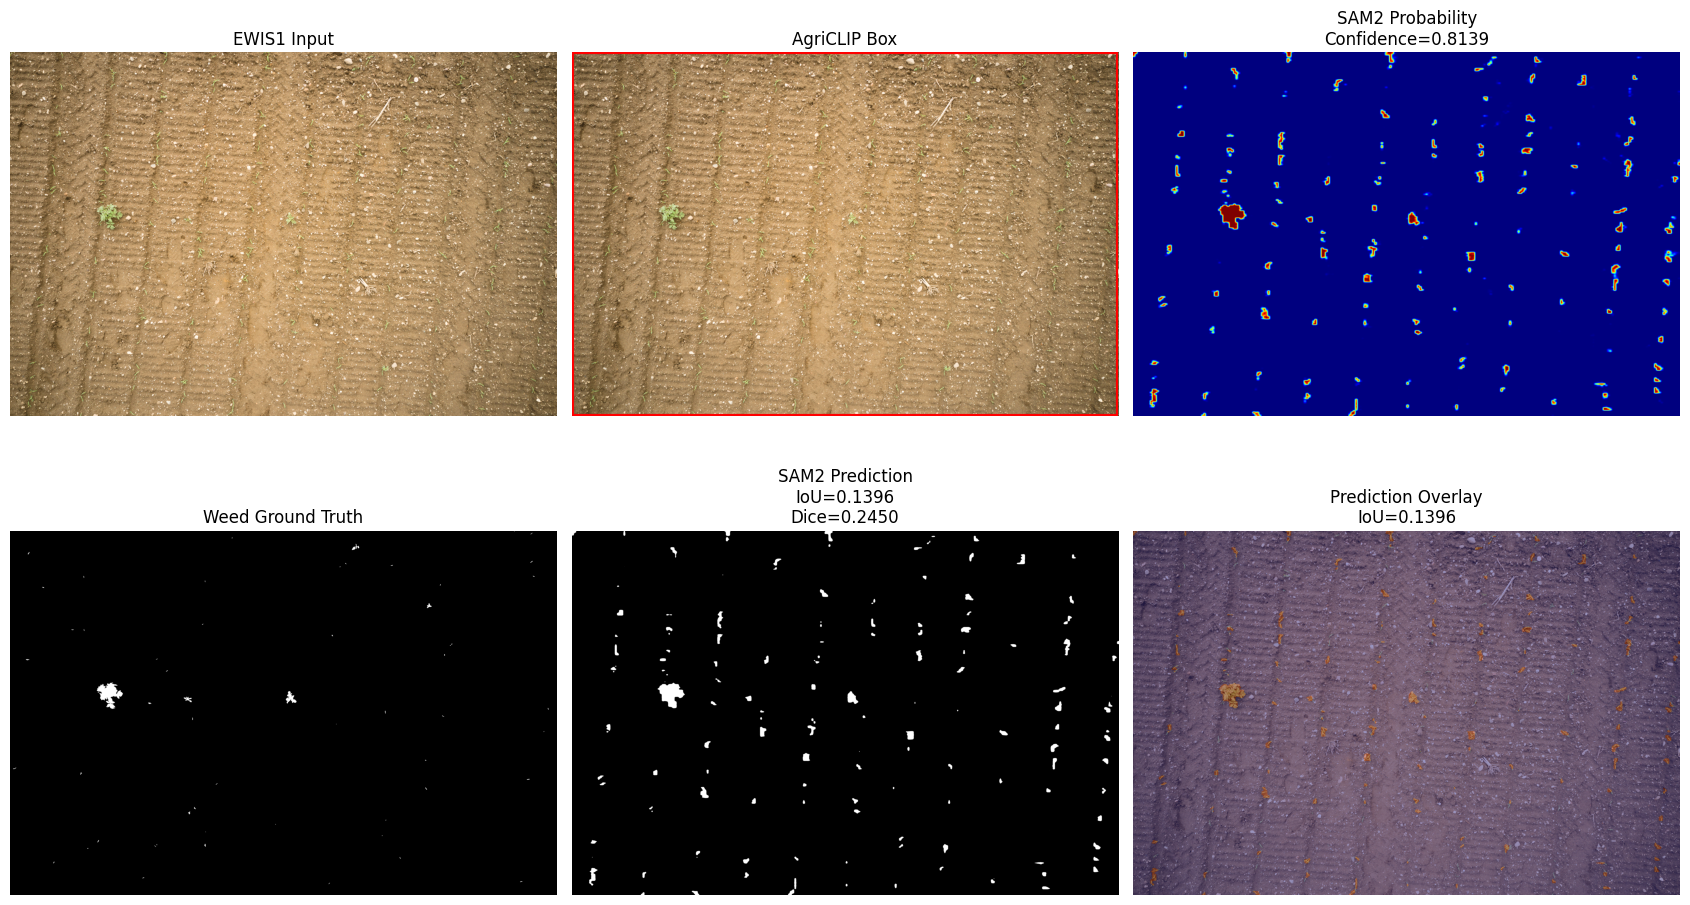

In [92]:
#Complete visualization 
fig, ax = plt.subplots(
    2,
    3,
    figsize=(17, 10)
)

# Input
ax[0, 0].imshow(image)

ax[0, 0].set_title(
    "EWIS1 Input"
)

ax[0, 0].axis("off")


# AgriCLIP box
ax[0, 1].imshow(image)

x1, y1, x2, y2 = agriclip_box

ax[0, 1].add_patch(
    plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=3
    )
)

ax[0, 1].set_title(
    "AgriCLIP Box"
)

ax[0, 1].axis("off")


# Probability
ax[0, 2].imshow(
    probability,
    cmap="jet"
)

ax[0, 2].set_title(
    f"SAM2 Probability\n"
    f"Confidence={confidence:.4f}"
)

ax[0, 2].axis("off")


# GT
ax[1, 0].imshow(
    gt_mask,
    cmap="gray"
)

ax[1, 0].set_title(
    "Weed Ground Truth"
)

ax[1, 0].axis("off")


# Prediction
ax[1, 1].imshow(
    pred_mask,
    cmap="gray"
)

ax[1, 1].set_title(
    f"SAM2 Prediction\n"
    f"IoU={ewis1_metrics['iou']:.4f}\n"
    f"Dice={ewis1_metrics['dice']:.4f}"
)

ax[1, 1].axis("off")


# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.4
)

ax[1, 2].set_title(
    f"Prediction Overlay\n"
    f"IoU={ewis1_metrics['iou']:.4f}"
)

ax[1, 2].axis("off")

plt.tight_layout()
plt.show()


In [93]:
#Full evaluation loop 
ewis1_results = []

print(
    "Total EWIS1 images:",
    len(ewis1_pairs)
)

for idx in tqdm(
    range(len(ewis1_pairs)),
    desc="Evaluating EWIS1"
):

    try:

        # ------------------------------------------------
        # Load image and GT
        # ------------------------------------------------

        image = get_ewis1_image(idx)

        gt_mask = get_ewis1_mask(idx)


        # ------------------------------------------------
        # AgriCLIP box
        # ------------------------------------------------

        (
            agriclip_box,
            boxes,
            scores,
            topk_indices
        ) = generate_agriclip_box(
            image,
            top_k=32,
            margin=25
        )


        # ------------------------------------------------
        # SAM2
        # ------------------------------------------------

        (
            pred_mask,
            probability,
            confidence
        ) = sam2_predict_box(
            image,
            agriclip_box,
            threshold=0.5
        )


        # ------------------------------------------------
        # Metrics
        # ------------------------------------------------

        metrics = compute_binary_metrics(
            pred_mask,
            gt_mask
        )


        # ------------------------------------------------
        # Store result
        # ------------------------------------------------

        ewis1_results.append({

            "image_id":
                idx,

            "file_name":
                ewis1_pairs[idx]["image"].name,

            "iou":
                metrics["iou"],

            "dice":
                metrics["dice"],

            "precision":
                metrics["precision"],

            "recall":
                metrics["recall"],

            "sam2_confidence":
                float(confidence),

            "box_x1":
                int(agriclip_box[0]),

            "box_y1":
                int(agriclip_box[1]),

            "box_x2":
                int(agriclip_box[2]),

            "box_y2":
                int(agriclip_box[3]),
        })


    except Exception as e:

        print(
            f"\nERROR at image {idx}:"
        )

        print(
            e
        )

        continue
        








Total EWIS1 images: 88


Evaluating EWIS1:   0%|          | 0/88 [00:00<?, ?it/s]

In [95]:
# ============================================================
# CHECK EWI1S RESULT COLUMNS
# ============================================================

ewis1_results_df = pd.DataFrame(
    ewis1_results
)

print("Available columns:")
print(
    ewis1_results_df.columns.tolist()
)

print("\nFirst result:")
display(
    ewis1_results_df.head(1)
)

Available columns:
['image_id', 'file_name', 'iou', 'dice', 'precision', 'recall', 'sam2_confidence', 'box_x1', 'box_y1', 'box_x2', 'box_y2']

First result:


,image_id,file_name,iou,dice,precision,recall,sam2_confidence,box_x1,box_y1,box_x2,box_y2
0,0,Aholfing_20220525_Sorghum_008.png,0.139627,0.24504,0.144081,0.818736,0.813893,0,0,5463,3639


In [96]:
# ============================================================
# EWI1S — FINAL SUMMARY
# ============================================================

ewis1_results_df = pd.DataFrame(
    ewis1_results
)

print("=" * 70)
print("EWI1S — AGRICLIP + SAM2 FINAL RESULTS")
print("=" * 70)

print(
    "Successful images:",
    len(ewis1_results_df),
    "/",
    len(ewis1_pairs)
)

if len(ewis1_results_df) == 0:
    raise RuntimeError(
        "No successful EWI1S evaluations were recorded."
    )

# ------------------------------------------------------------
# Metrics that exist
# ------------------------------------------------------------

metric_columns = [
    "iou",
    "dice",
    "precision",
    "recall",
    "sam2_confidence"
]

existing_metrics = [
    col
    for col in metric_columns
    if col in ewis1_results_df.columns
]

# ------------------------------------------------------------
# Mean values
# ------------------------------------------------------------

mean_results = (
    ewis1_results_df[
        existing_metrics
    ].mean()
)

median_results = (
    ewis1_results_df[
        [
            col
            for col in ["iou", "dice"]
            if col in ewis1_results_df.columns
        ]
    ].median()
)

# ------------------------------------------------------------
# Print segmentation metrics
# ------------------------------------------------------------

print("\n")

if "iou" in mean_results.index:

    print(
        f"Mean SAM2 IoU:         "
        f"{mean_results['iou'] * 100:.2f}%"
    )

    print(
        f"Median SAM2 IoU:       "
        f"{median_results['iou'] * 100:.2f}%"
    )

if "dice" in mean_results.index:

    print(
        f"Mean Dice:             "
        f"{mean_results['dice'] * 100:.2f}%"
    )

if "precision" in mean_results.index:

    print(
        f"Mean Precision:        "
        f"{mean_results['precision'] * 100:.2f}%"
    )

if "recall" in mean_results.index:

    print(
        f"Mean Recall:           "
        f"{mean_results['recall'] * 100:.2f}%"
    )

if "sam2_confidence" in mean_results.index:

    print(
        f"Mean SAM2 Confidence:  "
        f"{mean_results['sam2_confidence']:.4f}"
    )

# ------------------------------------------------------------
# AgriCLIP box IoU if available
# ------------------------------------------------------------

if "agriclip_box_iou" in ewis1_results_df.columns:

    print(
        f"Mean AgriCLIP Box IoU: "
        f"{ewis1_results_df['agriclip_box_iou'].mean() * 100:.2f}%"
    )

else:

    print(
        "\nMean AgriCLIP Box IoU: "
        "not available in stored results"
    )

print("=" * 70)

EWI1S — AGRICLIP + SAM2 FINAL RESULTS
Successful images: 88 / 88


Mean SAM2 IoU:         9.81%
Median SAM2 IoU:       4.46%
Mean Dice:             15.54%
Mean Precision:        11.18%
Mean Recall:           53.47%
Mean SAM2 Confidence:  0.8238

Mean AgriCLIP Box IoU: not available in stored results


# DEBUGGING

In [98]:
# ============================================================
# EWI1S — SINGLE IMAGE DIAGNOSTIC
# ============================================================

TEST_IDX = 0

image = get_ewis1_image(TEST_IDX)
gt_mask = get_ewis1_mask(TEST_IDX)

# ------------------------------------------------------------
# AgriCLIP localization
# ------------------------------------------------------------

(
    agriclip_box,
    patch_boxes,
    scores,
    topk_indices
) = generate_agriclip_box(
    image,
    top_k=32,
    margin=25
)

# ------------------------------------------------------------
# GT box
# ------------------------------------------------------------

def mask_to_box_local(mask):
    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return None

    return np.array(
        [
            xs.min(),
            ys.min(),
            xs.max(),
            ys.max()
        ],
        dtype=np.float32
    )


def box_iou_local(box_a, box_b):

    if box_a is None or box_b is None:
        return np.nan

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0, ix2 - ix1)
    ih = max(0, iy2 - iy1)

    intersection = iw * ih

    area_a = (
        max(0, ax2 - ax1) *
        max(0, ay2 - ay1)
    )

    area_b = (
        max(0, bx2 - bx1) *
        max(0, by2 - by1)
    )

    union = (
        area_a +
        area_b -
        intersection
    )

    if union <= 0:
        return 0.0

    return intersection / union


gt_box = mask_to_box_local(
    gt_mask
)

box_iou_value = box_iou_local(
    agriclip_box,
    gt_box
)

# ------------------------------------------------------------
# SAM2
# ------------------------------------------------------------

(
    pred_mask,
    probability,
    confidence
) = sam2_predict_box(
    image,
    agriclip_box,
    threshold=0.5
)

metrics = compute_binary_metrics(
    pred_mask,
    gt_mask
)

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("=" * 70)
print("EWI1S SINGLE IMAGE DIAGNOSTIC")
print("=" * 70)

print(
    "Image:",
    TEST_IDX
)

print(
    "Image size:",
    image.size
)

print(
    "\nGT foreground:",
    int(gt_mask.sum())
)

print(
    "AgriCLIP box:",
    agriclip_box
)

print(
    "GT box:",
    gt_box
)

print(
    f"Box IoU: "
    f"{box_iou_value * 100:.2f}%"
)

print(
    "\nSelected patches:",
    len(topk_indices)
)

print(
    "Top-K indices:",
    topk_indices
)

print(
    "\nSAM2 confidence:",
    f"{confidence:.4f}"
)

print(
    f"SAM2 IoU: "
    f"{metrics['iou'] * 100:.2f}%"
)

print(
    f"SAM2 Dice: "
    f"{metrics['dice'] * 100:.2f}%"
)

print(
    f"Precision: "
    f"{metrics['precision'] * 100:.2f}%"
)

print(
    f"Recall: "
    f"{metrics['recall'] * 100:.2f}%"
)

print("=" * 70)

EWI1S SINGLE IMAGE DIAGNOSTIC
Image: 0
Image size: (5464, 3640)

GT foreground: 48261
AgriCLIP box: [   0    0 5463 3639]
GT box: [  31.    0. 5379. 3531.]
Box IoU: 94.99%

Selected patches: 32
Top-K indices: [35 46 38 39 28 45 41 40 21 37 14 16 43 23 31 47  1 30 10 32 34 17 36 29
  5  3 44 13 20 22  9 15]

SAM2 confidence: 0.8139
SAM2 IoU: 13.96%
SAM2 Dice: 24.50%
Precision: 14.41%
Recall: 81.87%


In [99]:
# ============================================================
# EWI1S GT MASK SANITY CHECK
# ============================================================

empty_count = 0
foreground_percentages = []

for idx in range(
    len(ewis1_pairs)
):

    mask = get_ewis1_mask(
        idx
    )

    foreground = (
        mask.sum()
    )

    if foreground == 0:
        empty_count += 1

    else:

        percentage = (
            foreground /
            mask.size *
            100
        )

        foreground_percentages.append(
            percentage
        )

print("=" * 70)
print("EWI1S GT MASK DIAGNOSTIC")
print("=" * 70)

print(
    "Total images:",
    len(ewis1_pairs)
)

print(
    "Empty masks:",
    empty_count
)

print(
    "Non-empty masks:",
    len(ewis1_pairs) -
    empty_count
)

if foreground_percentages:

    print(
        "Mean foreground %:",
        f"{np.mean(foreground_percentages):.2f}%"
    )

    print(
        "Min foreground %:",
        f"{np.min(foreground_percentages):.2f}%"
    )

    print(
        "Max foreground %:",
        f"{np.max(foreground_percentages):.2f}%"
    )

print("=" * 70)

EWI1S GT MASK DIAGNOSTIC
Total images: 88
Empty masks: 0
Non-empty masks: 88
Mean foreground %: 0.98%
Min foreground %: 0.01%
Max foreground %: 14.46%


In [97]:
# ============================================================
# SAVE EWIS1 AGRICLIP + SAM2 RESULTS
# ============================================================

results_csv = (
    EWIS1_OUTPUT_DIR
    / "ewis1_agriclip_sam2_final_results.csv"
)

summary_csv = (
    EWIS1_OUTPUT_DIR
    / "ewis1_agriclip_sam2_final_summary.csv"
)

ewis1_results_df.to_csv(
    results_csv,
    index=False
)

summary_df = pd.DataFrame({
    "Dataset": ["EWIS1"],

    "AgriCLIP Box IoU":
        [mean_results["agriclip_box_iou"] * 100],

    "SAM2 IoU":
        [mean_results["iou"] * 100],

    "Dice":
        [mean_results["dice"] * 100],

    "Precision":
        [mean_results["precision"] * 100],

    "Recall":
        [mean_results["recall"] * 100],

    "SAM2 Confidence":
        [mean_results["sam2_confidence"] * 100],
})

summary_df.to_csv(
    summary_csv,
    index=False
)

print("Results saved to:")
print(results_csv)

print("\nSummary saved to:")
print(summary_csv)

KeyError: 'agriclip_box_iou'

In [ ]:
#Convert to dataframe 
ewis1_results_df = pd.DataFrame(
    ewis1_results
)

print(
    "Results shape:",
    ewis1_results_df.shape
)

print(
    ewis1_results_df.head()
)

Results shape: (88, 11)
   image_id                          file_name       iou      dice  precision  \
0         0  Aholfing_20220525_Sorghum_008.png  0.139627  0.245040   0.144081   
1         1  Aholfing_20220525_Sorghum_010.png  0.119336  0.213226   0.134635   
2         2        Loew_20220505_Maize_006.png  0.267969  0.422674   0.415096   
3         3        Loew_20220505_Maize_012.png  0.271759  0.427375   0.418511   
4         4        Loew_20220505_Maize_018.png  0.421057  0.592597   0.769605   

     recall  sam2_confidence  box_x1  box_y1  box_x2  box_y2  
0  0.818736         0.813893       0       0    5463    3639  
1  0.512240         0.812647       0       0    3927    3639  
2  0.430534         0.707127       0    1015    5463    3639  
3  0.436623         0.754761       0       0    5463    3145  
4  0.481786         0.828479       0       0    1586    3145  


In [ ]:
#Mean Results 
mean_ewis1 = (
    ewis1_results_df[
        [
            "iou",
            "dice",
            "precision",
            "recall",
            "sam2_confidence"
        ]
    ]
    .mean()
)

print(
    "========== MEAN EWIS1 RESULTS =========="
)

print(
    mean_ewis1
)


========== MEAN EWIS1 RESULTS ==========
iou                0.099905
dice               0.160558
precision          0.123876
recall             0.424585
sam2_confidence    0.788997
dtype: float64


In [ ]:
#Percentage results 
print(
    "========== EWIS1 RESULTS (%) =========="
)

print(
    f"IoU:       {mean_ewis1['iou'] * 100:.2f}%"
)

print(
    f"Dice:      {mean_ewis1['dice'] * 100:.2f}%"
)

print(
    f"Precision: {mean_ewis1['precision'] * 100:.2f}%"
)

print(
    f"Recall:    {mean_ewis1['recall'] * 100:.2f}%"
)

print(
    f"Confidence:{mean_ewis1['sam2_confidence']:.4f}"
)

========== EWIS1 RESULTS (%) ==========
IoU:       9.99%
Dice:      16.06%
Precision: 12.39%
Recall:    42.46%
Confidence:0.7890


In [ ]:
#Best 5 
best_5 = (
    ewis1_results_df
    .sort_values(
        "iou",
        ascending=False
    )
    .head(5)
)

print(
    "========== BEST 5 EWIS1 IMAGES =========="
)

print(
    best_5[
        [
            "image_id",
            "file_name",
            "iou",
            "dice",
            "precision",
            "recall"
        ]
    ].to_string(
        index=False
    )
)

========== BEST 5 EWIS1 IMAGES ==========
 image_id                   file_name      iou     dice  precision   recall
       51   img_20210713_B2_1_016.png 0.694583 0.819768   0.875702 0.770551
        9 Loew_20220509_Maize_026.png 0.449889 0.620584   0.589550 0.655067
       65   img_20210813_C2_1_023.png 0.440931 0.612008   0.584868 0.641790
        4 Loew_20220505_Maize_018.png 0.421057 0.592597   0.769605 0.481786
       55   img_20210713_B3_1_014.png 0.416174 0.587744   0.483790 0.748599


In [ ]:
#Worst 5 
worst_5 = (
    ewis1_results_df
    .sort_values(
        "iou",
        ascending=True
    )
    .head(5)
)

print(
    "========== WORST 5 EWIS1 IMAGES =========="
)

print(
    worst_5[
        [
            "image_id",
            "file_name",
            "iou",
            "dice",
            "precision",
            "recall"
        ]
    ].to_string(
        index=False
    )
)

========== WORST 5 EWIS1 IMAGES ==========
 image_id                 file_name      iou     dice  precision   recall
       50 img_20210713_B2_1_008.png 0.000000 0.000000   0.000000 0.000000
       38 img_20210629_A1_2_027.png 0.000000 0.000000   0.000000 0.000000
       71 img_20210824_D1_3_021.png 0.000000 0.000000   0.000000 0.000000
       48 img_20210713_B1_3_019.png 0.000064 0.000127   0.000064 0.187181
       72 img_20210824_D1_3_023.png 0.000085 0.000170   0.000085 0.024528


In [ ]:
#Save results 

results_csv = (
    EWIS1_OUTPUT_DIR
    / "ewis1_agriclip_sam2_results.csv"
)

ewis1_results_df.to_csv(
    results_csv,
    index=False
)

print(
    "Saved:",
    results_csv
)

Saved: /home/zahranadeem/thesis/results/ewis1_agriclip_sam2/ewis1_agriclip_sam2_results.csv


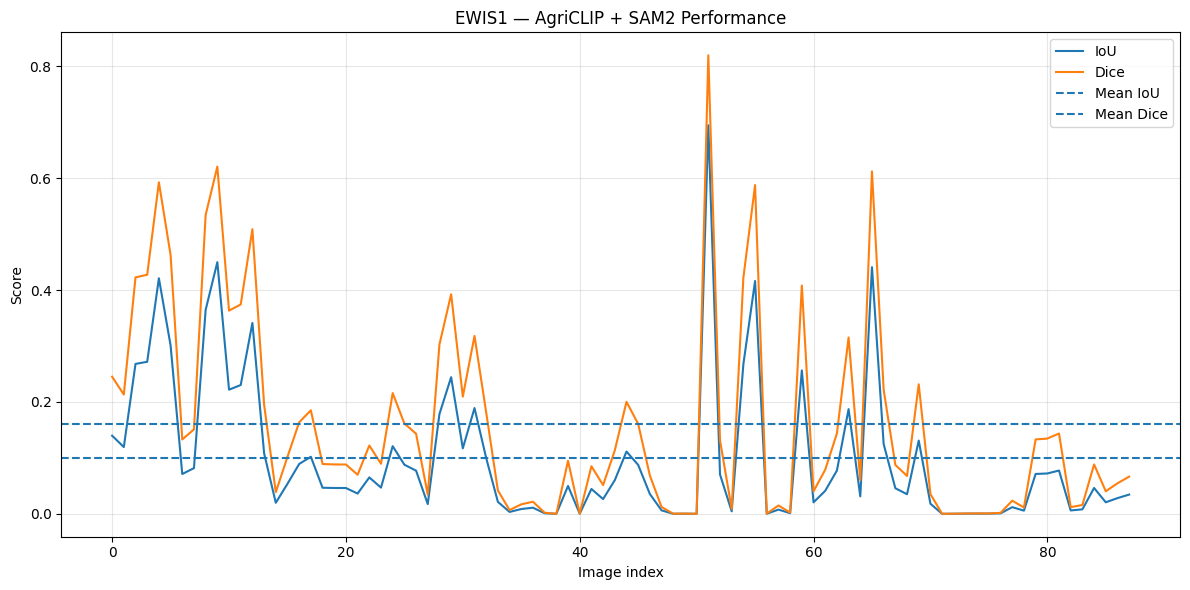

In [ ]:
#Plot 
plt.figure(
    figsize=(12, 6)
)

x = np.arange(
    len(ewis1_results_df)
)

plt.plot(
    x,
    ewis1_results_df["iou"],
    label="IoU"
)

plt.plot(
    x,
    ewis1_results_df["dice"],
    label="Dice"
)

plt.axhline(
    mean_ewis1["iou"],
    linestyle="--",
    label="Mean IoU"
)

plt.axhline(
    mean_ewis1["dice"],
    linestyle="--",
    label="Mean Dice"
)

plt.xlabel(
    "Image index"
)

plt.ylabel(
    "Score"
)

plt.title(
    "EWIS1 — AgriCLIP + SAM2 Performance"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
#Box size diagnostic 
image_width = []
image_height = []

for idx in range(
    len(ewis1_pairs)
):

    img = get_ewis1_image(idx)

    w, h = img.size

    image_width.append(w)
    image_height.append(h)

ewis1_results_df["image_width"] = (
    image_width
)

ewis1_results_df["image_height"] = (
    image_height
)

ewis1_results_df["box_area_ratio"] = (
    (
        (
            ewis1_results_df["box_x2"]
            - ewis1_results_df["box_x1"]
        )
        *
        (
            ewis1_results_df["box_y2"]
            - ewis1_results_df["box_y1"]
        )
    )
    /
    (
        ewis1_results_df["image_width"]
        *
        ewis1_results_df["image_height"]
    )
)

print(
    ewis1_results_df[
        [
            "file_name",
            "iou",
            "box_area_ratio"
        ]
    ].head()
)

                           file_name       iou  box_area_ratio
0  Aholfing_20220525_Sorghum_008.png  0.139627        0.999542
1  Aholfing_20220525_Sorghum_010.png  0.119336        0.718507
2        Loew_20220505_Maize_006.png  0.267969        0.720747
3        Loew_20220505_Maize_012.png  0.271759        0.863853
4        Loew_20220505_Maize_018.png  0.421057        0.250791


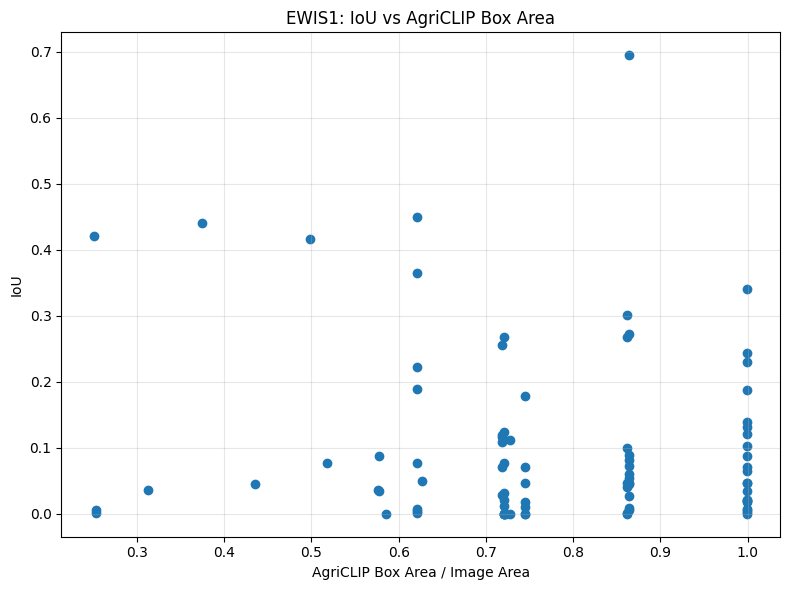

In [ ]:
#IoU vs box area 
plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    ewis1_results_df["box_area_ratio"],
    ewis1_results_df["iou"]
)

plt.xlabel(
    "AgriCLIP Box Area / Image Area"
)

plt.ylabel(
    "IoU"
)

plt.title(
    "EWIS1: IoU vs AgriCLIP Box Area"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


In [ ]:
#Save 
ewis1_summary = pd.DataFrame({
    "Dataset": ["EWIS1"],
    "IoU": [mean_ewis1["iou"] * 100],
    "Dice": [mean_ewis1["dice"] * 100],
    "Precision": [mean_ewis1["precision"] * 100],
    "Recall": [mean_ewis1["recall"] * 100],
    "SAM2 Confidence": [
        mean_ewis1["sam2_confidence"]
    ]
})

print(
    ewis1_summary.to_string(
        index=False
    )
)

ewis1_summary.to_csv(
    EWIS1_OUTPUT_DIR
    / "ewis1_summary.csv",
    index=False
)

Dataset      IoU      Dice  Precision    Recall  SAM2 Confidence
  EWIS1 9.990539 16.055771  12.387573 42.458471         0.788997
